# DuckDB Masterclass — Capítulo 09
## Extensões cloud, Parquet e gestão segura de credenciais

**Edição didática para estudo autônomo e publicação**  
**Contexto:** Operations Analytics e telecomunicações | **Dados:** sintéticos  
**Roteiro:** hipótese → executar → validar → interpretar → desafio → autoavaliação.

> Execute as células **de cima para baixo** em um kernel limpo. Resultados reais só devem ser salvos depois da execução no seu ambiente. Não publique dados privados, credenciais ou caminhos absolutos.

## 09.1 — Objetivos e diagnóstico

- Consultar Parquet sem rede ou serviços pagos.
- Inspecionar disponibilidade de extensões `httpfs` e provedores.
- Descrever ciclo de credenciais sem expor segredos.
- Distinguir demonstração offline e operação em cloud.

**Pergunta de partida:** que risco operacional aparece quando utilizamos essa tecnologia de forma inadequada?

## 09.2 — Conceitos essenciais

Leituras remotas dependem de extensão, endpoint, autorização e rede. Um laboratório offline de Parquet confirma o formato e a consulta, mas **não** demonstra integração S3/Azure/GCS nem valida segurança de credenciais reais.

### 🗺️ Modelo visual — Extensões cloud, Parquet e gestão segura de credenciais

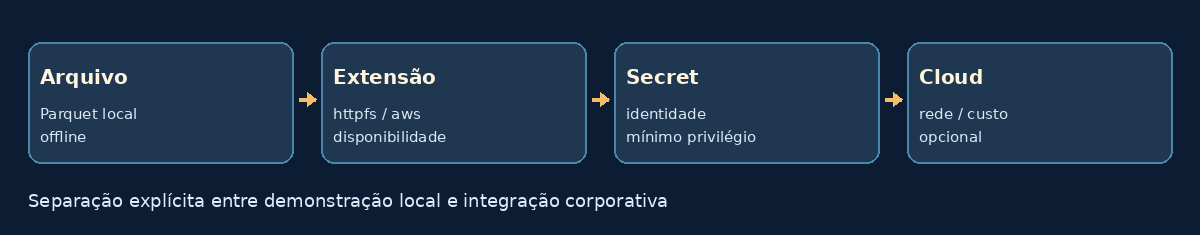

*Ilustração esquemática; não representa medição experimental.*

## 09.3 — Preparação e pré-requisitos

- Kernel recomendado: **Python (DuckDB Masterclass)**.
- Instale dependências ausentes no seu ambiente, fora do fluxo dos laboratórios.
- Cada arquivo produzido é sintético e deve ser salvo em pasta temporária ou `dados/` (ignorada pelo Git).
- Não execute instalação de extensões externas sem entender a necessidade, conectividade e eventuais custos.

## 09.4 — 🔬 Criar dados de telemetria em Parquet

**Hipótese / tarefa:** Persistir Parquet apenas em pasta temporária.

In [ ]:
import duckdb,tempfile
from pathlib import Path
from IPython.display import display
con=duckdb.connect(':memory:')
pasta_telemetria=tempfile.TemporaryDirectory()
arquivo_parquet=Path(pasta_telemetria.name)/'telemetria.parquet'
con.execute('CREATE TABLE telemetria AS SELECT i id,i%4 pop,i%100 latencia_ms FROM range(100) t(i)')
con.execute(f"COPY telemetria TO '{arquivo_parquet.as_posix()}' (FORMAT PARQUET)")
print('Parquet local gerado:',arquivo_parquet.name)

**Interpretação e limite:** Nenhum dado corporativo ou credencial é utilizado.

## 09.5 — 🔬 Consultar Parquet diretamente

**Hipótese / tarefa:** Agrupar latência por POP sem importar tabela persistente.

In [ ]:
query=f"SELECT pop,COUNT(*) n,ROUND(AVG(latencia_ms),2) latencia_media FROM read_parquet('{arquivo_parquet.as_posix()}') GROUP BY pop ORDER BY pop"
res=con.execute(query).df()
display(res)
assert int(res['n'].sum())==100

**Interpretação e limite:** Esta leitura é local, não uma consulta remota.

## 09.6 — 🔬 Inspecionar extensões

**Hipótese / tarefa:** Listar presença de httpfs, aws e azure sem instalar nem ativar serviços.

In [ ]:
extensoes=con.execute("""SELECT extension_name,installed,loaded FROM duckdb_extensions()
 WHERE extension_name IN ('httpfs','aws','azure') ORDER BY extension_name""").df()
display(extensoes)
print('Sem tentativa de conexão externa ou exibição de secrets.')

**Interpretação e limite:** Extensão disponível não equivale a autenticação habilitada.

## 09.7 — 🔬 Política de credenciais como exercício

**Hipótese / tarefa:** Produzir checklist operacional sem inserir tokens.

In [ ]:
controles=['Identidade com privilégio mínimo','Segredos fora do notebook e do Git',
'Rotação e revogação','Auditoria de acessos','Política de custo de egress e requisições']
for controle in controles: print('[ ]',controle)
assert len(controles)==5

**Interpretação e limite:** Não exibir `secret_string` ou configurações sensíveis.

## 09.8 — 🎯 Desafio profissional

Escreva uma política curta de acesso a S3 que funcione com identidades e perfis, sem registrar chaves em texto puro.

**Critério de aceite:** apresentar a consulta ou procedimento, verificar uma hipótese e explicar pelo menos uma limitação. Resolva antes de consultar a referência abaixo.

### 🧠 Solução comentada / critérios de conferência

Segredos devem estar fora de notebooks e Git; capacidade de conectar depende de autenticação, infraestrutura e autorização.

## 09.9 — Autoavaliação

1. Explique o recurso sem reproduzir o código.
2. O que foi efetivamente demonstrado?
3. Que caso-limite poderia invalidar a interpretação?
4. Como validar a resposta com `assert`, SQL ou inspeção do plano?
5. Quando aplicaria isso em operações de telecomunicações?

**Gabarito orientador:** consulte a solução comentada do desafio e compare sua resposta com os resultados efetivamente observados; não conclua propriedades de performance ou produção sem evidência.

## 09.10 — Referências, reprodução e publicação

- [Secret Manager](https://duckdb.org/docs/stable/configuration/secrets_manager)
- [httpfs](https://duckdb.org/docs/stable/core_extensions/httpfs/overview)
- [AWS S3](https://duckdb.org/docs/stable/core_extensions/httpfs/s3api.html)

**Notas de engenharia:** Nenhuma credencial real é necessária; serviços externos, custos e rede ficam fora do experimento.

**Checklist editorial:** executar `Restart & Run All` quando aplicável; salvar saídas úteis; revisar integridade, privacidade, dependências e gráficos antes do `git add`.